# 02 · 머신러닝 기초 — 회귀·분류와 성능 평가 (GMP 데이터)
### 실습으로 배우는 GMP AI — 강의 목차 ④ 머신러닝 모델 유형과 성능 비교

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/02_ML_Basics_Regression_Classification.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 회귀·분류 개념과 성능지표 ② **GMP 에서 올바른 데이터 분할**(시간 순 검증) ③ **데이터 누수(leakage)** 찾아내기 ④ 모델 유형 비교 ⑤ 과대적합 |
| **데이터** | 실제 정제 생산 1,005 배치 (예제 01과 동일) |
| **실행 환경** | CPU · 약 15분 |

> 이 노트북에서는 **모델이 실패하는 경우**도 그대로 보여줍니다.
> 실제 제조 데이터로 모델을 만들면 흔히 겪는 일이고, **왜 실패했는지 진단하는 능력**이 성능 숫자보다 중요하기 때문입니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
REPO = "https://raw.githubusercontent.com/StillWork/GMPAI/main/data/"
def load_data(name, **kw):
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else REPO + name, **kw)
df = load_data("tablet_batches.csv", parse_dates=["start_date"]).sort_values("start_date").reset_index(drop=True)
print("배치:", len(df), "| 기간:", df.start_date.min().date(), "~", df.start_date.max().date())

Note: you may need to restart the kernel to use updated packages.

배치: 1005 | 기간: 2018-11-01 ~ 2021-04-01


## 1. 지도학습 — 제조 데이터의 X 와 y
| 용어 | 제조 현장의 의미 | 예 |
|---|---|---|
| **X (특성)** | 공정 중 **이미 알 수 있는** 값 (CMA·CPP·IPC) | 원료 시험값, 타정 압력·속도, 중량·경도 |
| **y (목표)** | **나중에 시험실에서 측정**되는 결과 (CQA) | 용출률, 불순물 |
| **회귀** | 숫자 예측 | "용출률이 몇 %일까?" |
| **분류** | 범주 예측 | "불순물 위험 배치인가? (예/아니오)" |

> 이 구조가 **RTRT(실시간 출하시험)** 의 원리입니다 — 공정 데이터로 품질을 예측해 일부 시험을 대체 (예제 09)

In [2]:
CQA = ["dissolution_av", "dissolution_min", "impurities_total", "impurity_o", "impurity_l", "residual_solvent"]
ID_COLS = ["batch", "code", "strength", "size", "start", "start_date",
           "api_code", "api_batch", "smcc_batch", "lactose_batch", "starch_batch"]

def make_X(exclude=()):
    # CQA(정답)와 식별자를 제외한 숫자 특성 행렬을 만든다
    cols = [c for c in df.columns if c not in CQA + ID_COLS + list(exclude)]
    X = df[cols].select_dtypes("number")
    return X.fillna(X.median())

X = make_X()
y = df["dissolution_av"].values
print(f"특성 {X.shape[1]}개 / 배치 {X.shape[0]}개")
print("특성 예시:", list(X.columns[:8]))

특성 59개 / 배치 1005개
특성 예시: ['api_content', 'lactose_water', 'lactose_sieve0045', 'lactose_sieve015', 'lactose_sieve025', 'smcc_water', 'smcc_td', 'smcc_bd']


## 2. 성능지표 — 손으로 먼저 계산
### 회귀
| 지표 | 수식 | GMP 해석 |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ | "평균 ±2%p 오차" — 현장 보고에 적합 |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ | 큰 오차에 민감 — 안전 마진 설정 |
| **R²** | $1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ | 1=완벽, 0=평균 수준, **음수=평균보다 못함** |

In [3]:
y_true = np.array([93.8, 99.7, 97.3, 88.5, 91.0])     # 실제 용출률 (%)
y_pred = np.array([92.5, 96.2, 95.9, 90.8, 90.4])     # 모델 예측
err = y_true - y_pred
print(f"MAE={np.abs(err).mean():.3f}  RMSE={np.sqrt((err**2).mean()):.3f}  "
      f"R²={1-(err**2).sum()/((y_true-y_true.mean())**2).sum():.3f}")
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print(f"sklearn 확인: MAE={mean_absolute_error(y_true,y_pred):.3f}  "
      f"RMSE={np.sqrt(mean_squared_error(y_true,y_pred)):.3f}  R²={r2_score(y_true,y_pred):.3f}")

MAE=1.820  RMSE=2.076  R²=0.739


sklearn 확인: MAE=1.820  RMSE=2.076  R²=0.739


### 분류 — 혼동행렬과 GMP 의 비대칭 비용
| 실제 \ 예측 | 위험으로 예측 | 적합으로 예측 |
|---|---|---|
| **실제 불량** | TP (제대로 잡음) | **FN (놓침)** ⚠️ |
| **실제 적합** | FP (오경보) | TN |

| 지표 | 수식 | GMP 의미 |
|---|---|---|
| 정확도 | (TP+TN)/전체 | **불균형이면 무의미** |
| 정밀도 | TP/(TP+FP) | 경보를 믿을 수 있는가 (불필요한 조사 비용) |
| **재현율** | TP/(TP+FN) | **불량을 놓치지 않는가** (환자 안전·회수 위험) |
| F1 | 2PR/(P+R) | 둘의 균형 |
| ROC-AUC / PR-AUC | 곡선 아래 면적 | 임계값과 무관한 비교 |

In [4]:
TP, FN, FP, TN = 7, 3, 10, 80
prec, rec = TP / (TP + FP), TP / (TP + FN)
print(f"정확도={(TP+TN)/100:.2f}  정밀도={prec:.2f}  재현율={rec:.2f}  F1={2*prec*rec/(prec+rec):.2f}")
print("→ '모두 적합'이라고만 해도 정확도 0.90. 하지만 재현율 0 → 불량을 하나도 못 잡음")

정확도=0.87  정밀도=0.41  재현율=0.70  F1=0.52
→ '모두 적합'이라고만 해도 정확도 0.90. 하지만 재현율 0 → 불량을 하나도 못 잡음


## 3. ⭐⭐ 데이터를 어떻게 나눌 것인가 — 성능 숫자를 좌우하는 결정
| 분할 | 방법 | 현실성 |
|---|---|---|
| **무작위 분할** | 배치를 섞어 80:20 | ❌ 미래 배치를 미리 본 셈 |
| **제품별 분할** | 제품 코드를 통째로 평가셋 | 새 제품으로의 일반화 측정 |
| **시간 순 분할** | 과거 80% 학습 → **미래 20% 평가** | ✅ 실제 운영과 동일 (CPV·검증에 적합) |

In [5]:
from sklearn.model_selection import cross_val_score, KFold, GroupKFold
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=0)
cv_random = cross_val_score(rf, X, y, cv=KFold(5, shuffle=True, random_state=0), scoring="r2")
cv_product = cross_val_score(rf, X, y, cv=GroupKFold(5), groups=df["code"], scoring="r2")

n = len(df); cut = int(n * 0.8)
tr, te = np.arange(cut), np.arange(cut, n)          # 데이터는 생산일 순으로 정렬되어 있음
rf.fit(X.iloc[tr], y[tr]); pred_time = rf.predict(X.iloc[te])
r2_time = r2_score(y[te], pred_time)
print(f"① 무작위 5-겹 CV : R² = {cv_random.mean():6.3f} ± {cv_random.std():.3f}")
print(f"② 제품별 5-겹 CV : R² = {cv_product.mean():6.3f} ± {cv_product.std():.3f}")
print(f"③ 시간 순 분할   : R² = {r2_time:6.3f}   ← {df.start_date.iloc[cut].date()} 이후 배치로 평가")

① 무작위 5-겹 CV : R² =  0.450 ± 0.024
② 제품별 5-겹 CV : R² =  0.123 ± 0.165
③ 시간 순 분할   : R² = -0.002   ← 2020-11-01 이후 배치로 평가


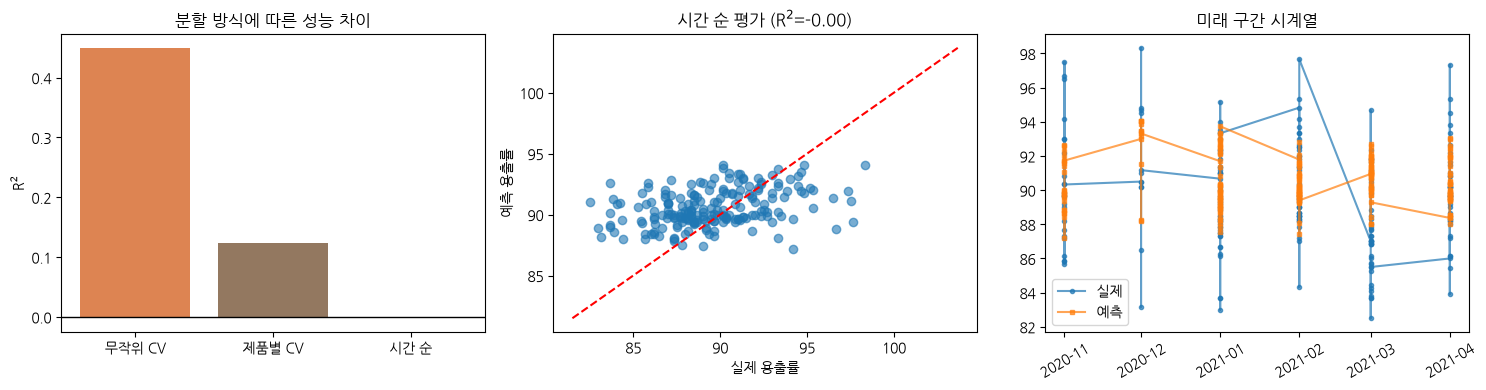

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(["무작위 CV", "제품별 CV", "시간 순"], [cv_random.mean(), cv_product.mean(), r2_time],
          color=["#DD8452", "#937860", "#4C72B0"])
ax[0].axhline(0, color="k", lw=1); ax[0].set_ylabel("R$^2$"); ax[0].set_title("분할 방식에 따른 성능 차이")
ax[1].scatter(y[te], pred_time, alpha=0.6)
lim = [y.min() - 1, y.max() + 1]; ax[1].plot(lim, lim, "r--")
ax[1].set_xlabel("실제 용출률"); ax[1].set_ylabel("예측 용출률"); ax[1].set_title(f"시간 순 평가 (R$^2$={r2_time:.2f})")
ax[2].plot(df["start_date"].iloc[te], y[te], "o-", ms=3, alpha=0.7, label="실제")
ax[2].plot(df["start_date"].iloc[te], pred_time, "s-", ms=3, alpha=0.7, label="예측")
ax[2].set_title("미래 구간 시계열"); ax[2].legend(); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

> ### 🚨 이 과정에서 가장 중요한 교훈
> 같은 데이터·같은 모델인데 **무작위 CV 는 R² 0.45, 미래 배치 예측은 R² ≈ 0** 입니다.
> 즉 **"용출률을 공정 데이터만으로 미리 맞히는 모델"은 이 데이터에서는 만들어지지 않았습니다.**
>
> 왜 무작위 CV 가 부풀려지는가:
> - 같은 캠페인(연속 생산)의 배치는 서로 매우 비슷합니다 → 학습·평가로 나뉘면 사실상 답을 보고 푸는 셈
> - 실제로 맞혀야 하는 것은 **아직 생산되지 않은 배치**입니다
>
> **GMP 적용 원칙**: 모델 검증 성능은 **시간 순(prospective) 분할**로 보고하고, 무작위 CV 는 개발 참고용으로만 씁니다.
> 이는 ICH Q10 의 **CPV(지속적 공정 검증)** 사고방식과 같습니다.
> 성능이 안 나오면 → 입력 변수가 부족하거나(예: 용출에 결정적인 과립 특성 미측정), 측정 노이즈가 신호보다 크다는 뜻입니다.

## 4. ⭐ 데이터 누수(Data Leakage) — 너무 좋은 성능은 의심하라
이번엔 **배치 수율(batch_yield)** 을 예측해 봅니다. R² 0.85 — 훌륭해 보입니다.

In [7]:
X_yield = make_X(exclude=["batch_yield"])
m = RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=0).fit(X_yield.iloc[tr], df.batch_yield[tr])
print(f"배치 수율 예측 (시간 순 분할) R² = {r2_score(df.batch_yield[te], m.predict(X_yield.iloc[te])):.3f}  ← 매우 높음!")
imp = pd.Series(m.feature_importances_, index=X_yield.columns).sort_values(ascending=False)
print("\n중요 변수 Top 5:"); print(imp.head(5).round(3).to_string())

배치 수율 예측 (시간 순 분할) R² = 0.850  ← 매우 높음!

중요 변수 Top 5:
tbl_yield            0.908
fct_min_hardness     0.007
SREL_startup_mean    0.005
tbl_fill_sd          0.004
tbl_min_hardness     0.004


tbl_yield 와 batch_yield 의 상관계수: 0.951



누수 변수 제거 후 R² = 0.162  ← 현실적인 성능


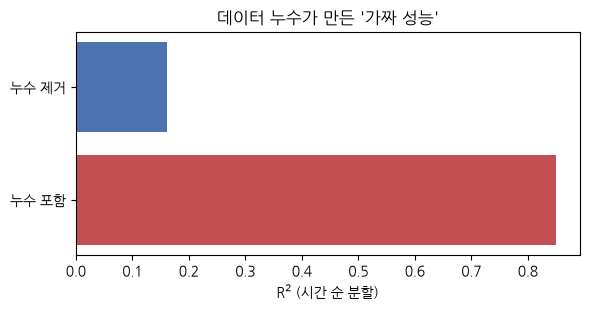

In [8]:
# 상위 변수 tbl_yield 는 '타정 단계 수율' — batch_yield 와 사실상 같은 값을 다른 시점에 잰 것
print("tbl_yield 와 batch_yield 의 상관계수:", round(df.tbl_yield.corr(df.batch_yield), 3))
LEAK = ["tbl_yield", "produced", "total_waste", "startup_waste"]      # 수율과 직결되는 변수들
X_clean = make_X(exclude=["batch_yield"] + LEAK)
m2 = RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=0).fit(X_clean.iloc[tr], df.batch_yield[tr])
print(f"\n누수 변수 제거 후 R² = {r2_score(df.batch_yield[te], m2.predict(X_clean.iloc[te])):.3f}  ← 현실적인 성능")
plt.figure(figsize=(6, 3.2))
plt.barh(["누수 포함", "누수 제거"], [0.85, r2_score(df.batch_yield[te], m2.predict(X_clean.iloc[te]))], color=["#C44E52", "#4C72B0"])
plt.xlabel("R$^2$ (시간 순 분할)"); plt.title("데이터 누수가 만든 '가짜 성능'"); plt.tight_layout(); plt.show()

> **데이터 누수 = 예측 시점에 알 수 없는 정보가 X 에 섞여 들어간 것.** GMP 현장의 흔한 사례:
> | 누수 유형 | 예 |
> |---|---|
> | 결과와 같은 정보 | 수율 예측에 '타정 수율'을 입력 |
> | 미래 정보 | 출하 판정 결과, 재작업 여부 |
> | 사후 입력 값 | 일탈 조사 후 수정된 기록 |
> | 전처리 누수 | 전체 데이터로 스케일링한 뒤 분할 (→ `Pipeline` 사용) |
>
> **점검법**: ① 성능이 지나치게 좋으면 의심 ② 중요 변수 Top 5 를 **공정 담당자와 함께** 확인
> ③ "이 값을 예측 시점에 정말 알 수 있나?" 질문 ④ 모델 카드에 입력 변수의 **측정 시점** 명시 (예제 08)

## 5. ⭐ AI 가 통하는 경우 — 불순물 위험 배치 분류
용출률은 실패했지만, **불순물**은 다릅니다. 불순물은 **원료(API) 품질**이라는 분명한 물리·화학적 원인이 있기 때문입니다.
`impurities_total > 0.2%` 인 배치를 **위험 배치**로 정의하고 분류 모델을 만듭니다.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             precision_score, recall_score, f1_score, classification_report)
y_cls = (df["impurities_total"] > 0.2).astype(int).values
print(f"위험 배치: 학습구간 {y_cls[tr].mean():.1%} / 평가구간 {y_cls[te].mean():.1%}")

clf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0, class_weight="balanced_subsample")
clf.fit(X.iloc[tr], y_cls[tr])
p = clf.predict_proba(X.iloc[te])[:, 1]
print(f"\nROC-AUC = {roc_auc_score(y_cls[te], p):.3f}   PR-AUC = {average_precision_score(y_cls[te], p):.3f} "
      f"(무작위 기준선 {y_cls[te].mean():.3f})")
print(classification_report(y_cls[te], (p >= 0.5).astype(int), target_names=["적합", "위험"], digits=3))

위험 배치: 학습구간 34.1% / 평가구간 24.4%



ROC-AUC = 0.946   PR-AUC = 0.825 (무작위 기준선 0.244)
              precision    recall  f1-score   support

          적합      0.901     0.961     0.930       152
          위험      0.846     0.673     0.750        49

    accuracy                          0.891       201
   macro avg      0.874     0.817     0.840       201
weighted avg      0.888     0.891     0.886       201



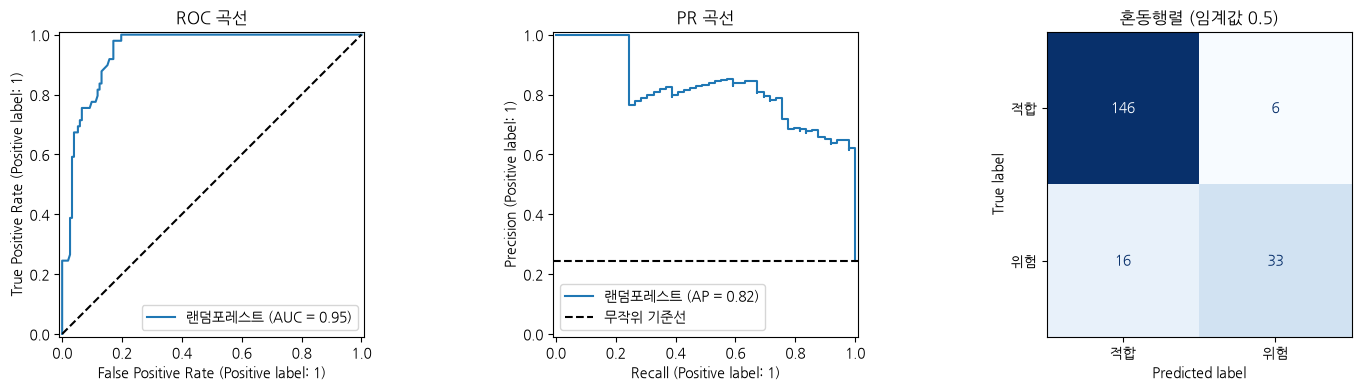

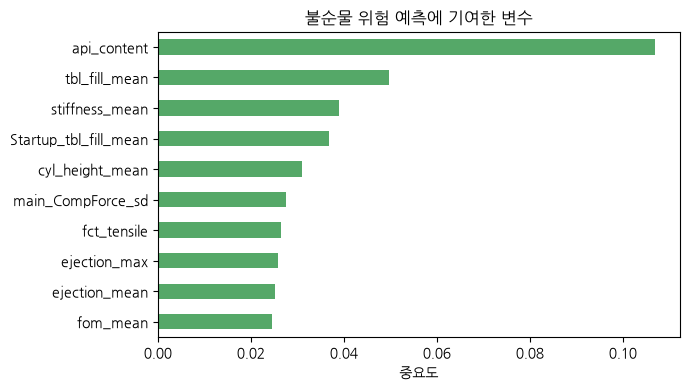

→ api_content(원료 API 함량) 등 원료 특성(CMA)이 상위 → 화학적으로 타당한 관계. 이것이 '진짜 신호'입니다.


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_cls[te], p, ax=ax[0], name="랜덤포레스트"); ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC 곡선")
PrecisionRecallDisplay.from_predictions(y_cls[te], p, ax=ax[1], name="랜덤포레스트")
ax[1].axhline(y_cls[te].mean(), color="k", ls="--", label="무작위 기준선"); ax[1].legend(); ax[1].set_title("PR 곡선")
ConfusionMatrixDisplay(confusion_matrix(y_cls[te], (p >= 0.5).astype(int)), display_labels=["적합", "위험"]).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title("혼동행렬 (임계값 0.5)")
plt.tight_layout(); plt.show()

imp = pd.Series(clf.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot.barh(figsize=(7, 4), color="#55A868"); plt.xlabel("중요도"); plt.title("불순물 위험 예측에 기여한 변수"); plt.tight_layout(); plt.show()
print("→ api_content(원료 API 함량) 등 원료 특성(CMA)이 상위 → 화학적으로 타당한 관계. 이것이 '진짜 신호'입니다.")

> **두 사례의 교훈**
> | 목표 | 미래 예측 성능 | 이유 |
> |---|---|---|
> | 용출률 | R² ≈ 0 (실패) | 결정적 입력(과립 특성 등)이 측정되지 않음, 측정 노이즈 큼 |
> | 불순물 위험 | ROC-AUC ≈ 0.95 (성공) | **원료 품질 → 불순물** 이라는 분명한 인과 경로가 데이터에 있음 |
>
> **AI 는 데이터에 없는 신호를 만들어내지 못합니다.** 성능이 안 나오면 알고리즘을 바꾸기 전에
> **"무엇을 측정하고 있지 않은가"** 를 물어야 합니다 → PAT 도입(예제 09)의 근거가 됩니다.

## 6. 모델 유형 비교 (신호가 있는 문제에서)
| 계열 | 모델 | 특징 | 스케일링 |
|---|---|---|---|
| 선형 | 로지스틱 회귀 | 계수 해석이 쉬워 **규제 설명에 유리** | 필요 |
| 거리 | kNN | 비슷한 과거 배치 참조 | 필요 |
| 트리 | 결정트리 | 규칙으로 설명 가능 | 불필요 |
| 앙상블 | 랜덤포레스트·부스팅 | 대체로 성능 우수 | 불필요 |

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier

models = {
    "기준선(다수 클래스)": DummyClassifier(strategy="prior"),
    "로지스틱회귀": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "결정트리": DecisionTreeClassifier(max_depth=4, random_state=0, class_weight="balanced"),
    "랜덤포레스트": RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0, class_weight="balanced_subsample"),
    "그래디언트부스팅": GradientBoostingClassifier(random_state=0),
}
rows = []
for name, m in models.items():
    m.fit(X.iloc[tr], y_cls[tr]); pr = m.predict_proba(X.iloc[te])[:, 1]; pd_ = (pr >= 0.5).astype(int)
    rows.append({"모델": name, "정밀도": precision_score(y_cls[te], pd_, zero_division=0),
                 "재현율": recall_score(y_cls[te], pd_), "F1": f1_score(y_cls[te], pd_),
                 "ROC-AUC": roc_auc_score(y_cls[te], pr), "PR-AUC": average_precision_score(y_cls[te], pr)})
pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).round(3)

,모델,정밀도,재현율,F1,ROC-AUC,PR-AUC
3,결정트리,0.563,1.000,0.721,0.977,0.899
5,그래디언트부스팅,0.712,0.857,0.778,0.927,0.866
4,랜덤포레스트,0.846,0.673,0.750,0.946,0.825
1,로지스틱회귀,0.373,0.776,0.503,0.828,0.708
2,kNN,0.530,0.898,0.667,0.868,0.560
0,기준선(다수 클래스),0.000,0.000,0.000,0.500,0.244


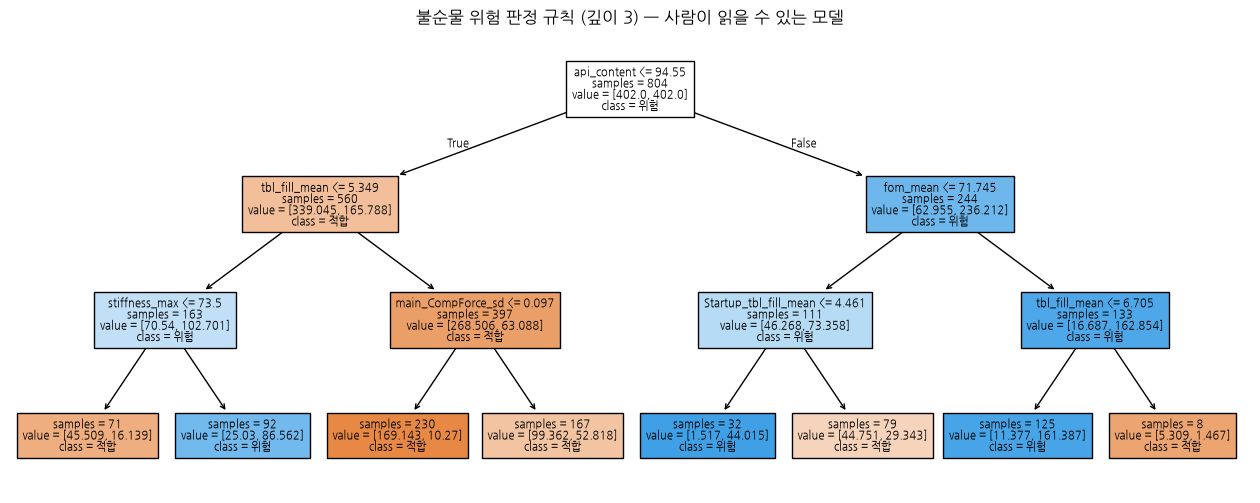

In [12]:
# 결정트리는 '규칙'으로 보여줄 수 있어 규제 대응·현장 교육에 유리합니다
from sklearn.tree import plot_tree
dt = DecisionTreeClassifier(max_depth=3, random_state=0, class_weight="balanced").fit(X.iloc[tr], y_cls[tr])
plt.figure(figsize=(16, 6))
plot_tree(dt, feature_names=list(X.columns), class_names=["적합", "위험"], filled=True, fontsize=8, impurity=False)
plt.title("불순물 위험 판정 규칙 (깊이 3) — 사람이 읽을 수 있는 모델"); plt.show()

## 7. 과대적합 — 복잡한 모델이 항상 좋지는 않다

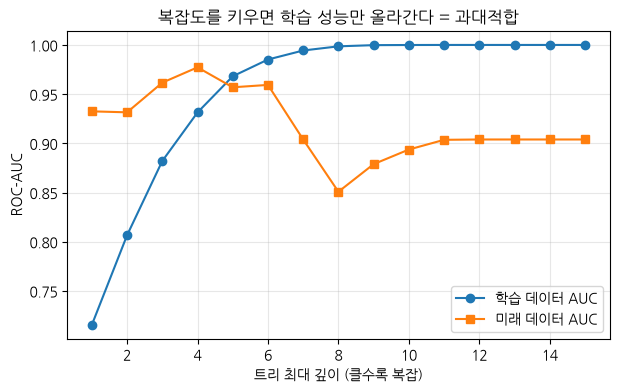

→ GMP 에서는 성능이 조금 낮더라도 단순하고 설명 가능한 모델이 유리한 경우가 많습니다.


In [13]:
depths = range(1, 16)
tr_s, te_s = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0, class_weight="balanced").fit(X.iloc[tr], y_cls[tr])
    tr_s.append(roc_auc_score(y_cls[tr], t.predict_proba(X.iloc[tr])[:, 1]))
    te_s.append(roc_auc_score(y_cls[te], t.predict_proba(X.iloc[te])[:, 1]))
plt.figure(figsize=(7, 4))
plt.plot(depths, tr_s, "o-", label="학습 데이터 AUC"); plt.plot(depths, te_s, "s-", label="미래 데이터 AUC")
plt.xlabel("트리 최대 깊이 (클수록 복잡)"); plt.ylabel("ROC-AUC"); plt.legend(); plt.grid(alpha=0.3)
plt.title("복잡도를 키우면 학습 성능만 올라간다 = 과대적합"); plt.show()
print("→ GMP 에서는 성능이 조금 낮더라도 단순하고 설명 가능한 모델이 유리한 경우가 많습니다.")

## 🧪 LLM 코딩 과제
```
pandas 데이터프레임 df(제약 정제 1005배치, start_date 순 정렬)와 특성행렬 X 가 있어.
목표를 impurities_total > 0.2 (위험 배치)로 하고, 시간 순 80:20 분할로
로지스틱회귀와 랜덤포레스트의 PR 곡선을 한 그래프에 그려줘.
그리고 임계값을 0.1~0.9까지 바꿔가며 재현율과 정밀도가 어떻게 변하는지 표로 보여줘. 한글 주석을 달아줘.
```

In [14]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리 — GMP AI 성능 평가 체크리스트
1. **분할 방식을 먼저 정한다** — 운영 상황과 같게. 보통 **시간 순(prospective) 분할**
2. **기준선과 비교한다** — 평균 예측(회귀)/다수 클래스(분류)보다 나은가
3. **너무 좋으면 의심한다** — 데이터 누수 점검 (중요 변수를 공정 담당자와 확인)
4. **불균형이면 정확도 대신** 재현율·PR-AUC
5. **실패도 결과다** — "예측 불가"는 PAT 도입·추가 계측의 근거가 된다
6. 데이터 기간·분할 방식·전처리를 **모델 카드에 기록** (예제 08)

➡️ **다음 예제 03**: 모델 이전의 기본기 — **SPC 관리도·공정능력(Cp/Cpk)과 다변량 SPC**